In [1]:
#Imports
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from subprocess import run, PIPE
import sys
import os
import gc
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator
import xarray as xr
import netCDF4 as nc
import pandas as pd
import cartopy.feature as cfeature

from scipy.stats import linregress


from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library

import dask.distributed
import multiprocessing
from subprocess import run, PIPE
import sys
import glob, os
import matplotlib.ticker as ticker

In [2]:
# some hand written plot scripts
import numpy as np
# import sys
# sys.path.append('/home/b/b381815/python_functions/')
import matplotlib as mpl
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from healpix_plot import default_plot, get_listed_colormap, get_diverging_colormap
#from healpix_plot_hatches import default_plot_hatch
import easygems.healpix as egh

# from healpix_functions import change_zoom_level

mpl.rc('font', **{'size': 16})
proj = ccrs.Mollweide()

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/hourly_precip/mask_01_IFS_2.8-FESOM_5_deep_on_hourly_precip_07_24_2020.nc')['dry']
ifs_plot = ifs_off[12,:]

In [5]:
print(ifs_plot)

<xarray.DataArray 'dry' (value: 50331648)> Size: 201MB
[50331648 values with dtype=float32]
Coordinates:
    time     datetime64[ns] 8B 2020-07-24T12:00:00
    lon      (value) float64 403MB ...
    lat      (value) float64 403MB ...
Dimensions without coordinates: value
Attributes:
    CDI_grid_type:  unstructured


In [6]:
def default_plot(
    data, 
    cmap='viridis', 
    ax='Mollweide', 
    add_coastlines=False, 
    add_rivers_lakes=False,
    topography=None,
    fill_lakes=True,
    add_colorbar=True, 
    levels=None,
    extend='neither',
    add_gridlines=False,
    dpi=300, 
    proj_kwargs={},
    cbar_kwargs={}, 
    rivers_lakes_kwargs={},
    topography_kwargs={},
    coastline_kwargs={},
    grid_kwargs={},
    **kwargs
):
    """

    Parameters
    ----------
    data : np.ndarray, shape (N,)
        Needs to be on a healpix grid, i.e., N needs to be divisibel by 12 * (2**zoom)**2
    cmap : string, optional, by default 'viridis'
    ax : string or cartopy.ccrs, optional, by default 'Mollweide'
        Possible string values:
        - 'Mollweide'
        - 'PlateCarree'
        - 'Orthographic'
    add_coaslines : bool, optional, by default False
    add_rivers_lakes : bool, optional, by default False
    fill_lakes  bool, optional, by default True
        Only relevent if `add_rivers_lakes=True`. Whether to plot shading within lakes
        this makes them better visible but might hinder seeing the variable shading
    topography : np.ndarray, shape (N,), optional, by default None
        Plot elevation contourlines based on the data passed.
    add_colorbar : bool, optional, by default True
    levels : np.ndarray, optional, by default None
        Can be used to set manual (non equidistant) color levels
    extend : string, optional, one of {'neither', 'min', 'max', 'both'}, by default 'neither'
    add_gridlines : bool, optional, by default False
    dpi : int, optional, by default 150
        Plot resolution. NOTE: sometimes artifacts apear around the zero meridian, changing
        the resoltion might solve this. 
    proj_kwargs : dict, optional
        Keyword arguments passed on to ccrs.<Projection>. Only relevent if ax is a string
        specifying a projection. The allowed values depend on the projection:
        - 'Mollweide': 'central_longitude'
        - 'PlateCarree': 'central_longitude'
        - 'Orthographic': 'central_longitude', 'central_latitude'
    cbar_kwargs : dict, optional
        Keyword arguments passed on to `plt.colorbar`
    coastline_kwargs : dict, optional
        Keyword arguments passed on to `ax.coastlines`
    topography_kwargs : dict, optional
        Keyword arguments passed on to `ax.contour`
    grid_kwargs : dict, optional
        Keyword arguments apssed on to `ax.gridlines`
    **kwargs : optional
        Keyword arguments passed on to `ax.imshow`

    Returns
    -------
    fig, ax, map_: tuple

    Additional information
    ----------------------
    List of cartopy projections: https://scitools.org.uk/cartopy/docs/v0.15/crs/projections.html
    """
    if isinstance(ax, str):
        proj = getattr(ccrs, ax)(**proj_kwargs)
        # increase transform resolution via
        # https://stackoverflow.com/questions/59020032/how-to-plot-a-filled-polygon-on-a-map-in-cartopy
        proj._threshold /= 1000.
        fig, ax = plt.subplots(
            figsize=(20, 10), 
            dpi=dpi, 
            subplot_kw={'projection': proj},
        )
        ax.set_global()
    else:
        fig = plt.gcf()
        
    if add_coastlines:
        defaults = {'color': 'gray', 'lw': .5}
        defaults.update(coastline_kwargs)
        ax.coastlines(**defaults)
    ax.set_extent([-180, 180, 30, 60], crs=ccrs.PlateCarree())

    if add_rivers_lakes:
        defaults = dict(
            alpha=1,
            facecolor='none',                
            edgecolor='cornflowerblue', 
            color='cornflowerblue', 
            linewidth=.5,
        )
        defaults.update(rivers_lakes_kwargs)
        if fill_lakes:
            ax.add_feature(
                cfeature.LAKES.with_scale('50m'), 
                alpha=.2,
                facecolor='cornflowerblue',                
                edgecolor='none', 
            )
        ax.add_feature(
            cfeature.LAKES.with_scale('50m'), 
            # alpha=1,
            # facecolor='none',                
            # edgecolor='cornflowerblue', 
            **defaults
        )
        ax.add_feature(
            cfeature.RIVERS,
            # color='cornflowerblue',
            # alpha=1,
            **defaults
        )

    if topography is not None:
        defaults = dict(
            colors='gray',
            levels=range(1000, 10_000, 1000),
            linewidths=.5,
        )
        defaults.update(topography_kwargs)
        
        _, _, nx, ny = np.array(ax.bbox.bounds, dtype=int)
        xlims = ax.get_xlim()
        ylims = ax.get_ylim() 
        im = egh.healpix_resample(
            topography, 
            xlims, ylims, 
            nx, ny, 
            ax.projection, 
            method='linear', 
            nest=True)
        
        map_ = ax.contour(
            im, 
            extent=xlims + ylims, 
            origin="lower",
            **defaults
        )

    if levels is not None:
        if isinstance(cmap, str):
            cmap = get_listed_colormap(levels, cmap, extend)
            kwargs.update({
                'vmin': levels[0], 
                'vmax': levels[-1],
        })
        else: 
            if isinstance(cmap, mpl.colors.ListedColormap):  # convert back to color list 
                if extend == 'max':
                    cmap = np.concatenate([cmap.colors, [cmap.get_over()]])
                elif extend == 'min':
                    cmap = np.concatenate([[cmap.get_under()], cmap.colors])
                elif extend == 'both':
                    cmap = np.concatenate([[cmap.get_under()], cmap.colors, [cmap.get_over()]])
                else:
                    cmap = cmap.colors
                    
            cmap, norm = mpl.colors.from_levels_and_colors(levels, cmap, extend=extend)
            kwargs.update({
            'norm': norm, 
            })
        cbar_kwargs.update({
            'ticks': levels,
            # 'boundaries': np.arange(len(levels)),
        })
    
    _, _, nx, ny = np.array(ax.bbox.bounds, dtype=int)
    xlims = ax.get_xlim()
    ylims = ax.get_ylim()

    im = egh.healpix_resample(
        data, 
        xlims, ylims, 
        nx, ny, 
        ax.projection, 
        method='nearest', 
        nest=True,
    )
   
    map_ = ax.imshow(
        im, 
        extent=xlims + ylims, 
        origin="lower", 
        cmap=cmap, 
        interpolation='none',
        **kwargs,
        rasterized=True
    )

    if add_gridlines:
        ax.gridlines(**grid_kwargs)

    if add_colorbar:
        #plt.colorbar(map_, ax=ax,shrink=.8, fraction=.03, extend=extend, **cbar_kwargs)
        plt.colorbar(map_, ax=ax,shrink=1.2,pad=0.05, fraction=.08, extend=extend,orientation='horizontal', **cbar_kwargs)

    return fig, ax, map_

In [ ]:
print(ifs_plot)

In [ ]:
fig, ax, map_ = default_plot(
    ifs_plot,                          # xarray, not .values
    cmap=mpl.colors.ListedColormap(['none', 'red']),
    levels=None,                       # skip the levels/norm path entirely
    extend='neither',
    add_coastlines=True,
    add_colorbar=False,                # no colorbar
    ax='PlateCarree',
    proj_kwargs={'central_longitude': 0},
    vmin=0,
    vmax=1,
)
plt.savefig('/home/jwille/images/global_paper/IFS_2.8_off_example_01_precip_24_07_2020_12z.pdf',format='pdf', bbox_inches='tight')
plt.savefig('/home/jwille/images/global_paper/IFS_2.8_off_example_01_precip_24_07_2020_12z.png',bbox_inches='tight',dpi=600)

In [7]:
cesm2 = xr.open_dataset('/net/atmos/data/CESM2-LE/1hr/PRECT/b.e21.BHISTsmbb.f09_g17.LE2-1011.001.cam.h4.PRECT.1850010100-1860010100.nc')['PRECT']



cesm2_plot = cesm2[3678,:,:]

In [8]:
cesm2_plot = cesm2_plot * 3600 * 1000
cesm2_plot = xr.where(cesm2_plot > 0.1, 1,0)

In [9]:
print(cesm2_plot.sum())

<xarray.DataArray 'PRECT' ()> Size: 8B
array(11079)
Coordinates:
    time     object 8B 1850-06-03 06:00:00


In [10]:
print(cesm2_plot)

<xarray.DataArray 'PRECT' (lat: 192, lon: 288)> Size: 442kB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(192, 288))
Coordinates:
  * lat      (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
    time     object 8B 1850-06-03 06:00:00


In [11]:
def plot_cesm2_binary(data):
    """
    Plot a regional map (30-60N) of binary CESM2 data,
    coloring 1s red and 0s transparent.
    
    Parameters
    ----------
    data : xarray.DataArray
        Binary data with (lat, lon) coordinates.
    
    Returns
    -------
    fig, ax : tuple
    """
    trend = data.squeeze()
    lat = trend['lat'].values
    lon = trend['lon'].values

    # Compute grid boundaries for pcolormesh
    dlon = np.mean(np.diff(lon))
    dlat = np.mean(np.diff(lat))
    lon_b = np.concatenate(([lon[0] - dlon/2], lon + dlon/2))
    lat_b = np.concatenate(([lat[0] - dlat/2], lat + dlat/2))
    LonB, LatB = np.meshgrid(lon_b, lat_b)

    # Set up PlateCarree projection restricted to 30-60N
    proj = ccrs.PlateCarree(central_longitude=0)
    fig, ax = plt.subplots(figsize=(20, 6), subplot_kw={'projection': proj})
    ax.set_extent([-180, 180, 30, 60], crs=ccrs.PlateCarree())

    # Binary colormap: transparent for 0, red for 1
    cmap = mpl.colors.ListedColormap(['none', 'red'])
    norm = mpl.colors.BoundaryNorm([0, 0.5, 1], ncolors=2)

    im = ax.pcolormesh(
        LonB, LatB, trend.values,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        norm=norm,
        shading='flat',
    )
    im.set_edgecolor('face')

    ax.coastlines(resolution='50m', color='gray', lw=0.5)
    #ax.set_title(f'Dry indicator – {str(data.time.values)[:16]}')

    return fig, ax



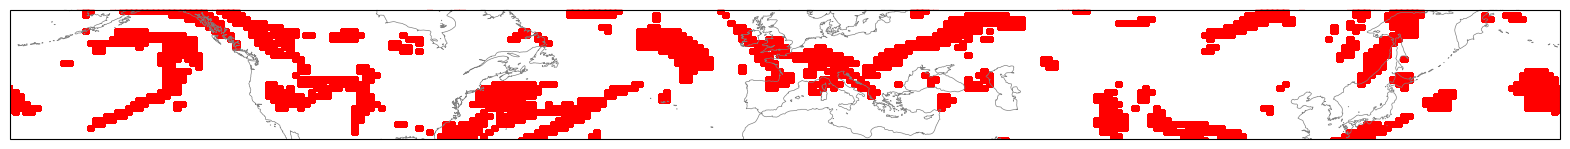

In [12]:
fig, ax = plot_cesm2_binary(cesm2_plot)

plt.savefig('/home/jwille/images/global_paper/CESM2_example_01_precip_03_06_1850_6z.pdf',format='pdf', bbox_inches='tight')
plt.savefig('/home/jwille/images/global_paper/CESM2_example_01_precip_03_06_1850_6z.png',bbox_inches='tight',dpi=600)